# Example 8.6 — PDB cross-links: HIV-1 protease ligands with crystal structures

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-opus-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:56:34Z
- **Contents:** 1 exchange · 9 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/8.6-pdb-cross-links-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 8.6-pdb-cross-links-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 8.6-pdb-cross-links-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/8.6-pdb-cross-links-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 8.6-pdb-cross-links-notebook-rerun.ipynb 8.6-pdb-cross-links-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Which compounds measured against HIV-1 protease also have a crystal structure in the PDB?

In [ ]:
# Call 1 · run_sql · ran 2026-11-24 04:56:32 UTC
arguments = {
    'sql': "-- HIV-1 protease target records (single proteins and complexes), by name pattern\nSELECT target_kind, count(*) AS records, sum(n_activities) AS measurements,\n       list(DISTINCT regexp_replace(name, ' \\[.*$', '') ORDER BY regexp_replace(name, ' \\[.*$', '')) AS base_names,\n       list(DISTINCT organism ORDER BY organism) AS organisms\nFROM target\nWHERE (regexp_matches(name, '^(Dimer of )?Gag-Pol polyprotein \\[(4[89]\\d|5[01]\\d)-(5[89]\\d|6[01]\\d)[,\\]]')\n OR ((name ILIKE 'HIV-1 protease%' OR name ILIKE 'Protease')\n     AND (organism ILIKE '%immunodeficiency virus%' OR organism IS NULL)))\nGROUP BY target_kind ORDER BY target_kind",
}
await replay.call(1, 'run_sql', arguments,
                  sha256='bd4b0cec813cd778184378e7b33889dabe19743597fb1a256a642d86ae3f9b4a')

**Call 1** · `run_sql` · recorded result · sha256 `bd4b0cec813c…`

_2 rows_

| target_kind | records | measurements | base_names | organisms |
| --- | --- | --- | --- | --- |
| complex | 76 | 2929 | Dimer of Gag-Pol polyprotein, HIV-1 Protease, HIV-1 Protease A Subtype, HIV-1 Protease A Subtype Mutant (V82F/I84V), HIV-1 Protease B Subtype, HIV-1 Protease B Subtype Mutant (V82F/I84V), HIV-1 Protease C Subtype, HIV-1 Protease C Subtype Mutant (V82F/I84V), HIV-1 Protease Mutant (L10I/L90M), HIV-1 Protease Mutant (M46I/I54V), HIV-1 Protease Mutant (V82A/I84V), HIV-1 Protease Mutant (V82F/I84V), HIV-1 Protease Mutant, MDR-HM, HIV-1 Protease Mutant, MDR-QM | None |
| polymer | 86 | 7062 | Gag-Pol polyprotein, HIV-1 Protease A Subtype Mutant (V82F/I84V) chain A, HIV-1 Protease A Subtype chain A, HIV-1 Protease B Subtype Mutant (V82F/I84V) chain A, HIV-1 Protease C Subtype Mutant (V82F/I84V) chain A, HIV-1 Protease C Subtype chain A, HIV-1 Protease Mutant (L10I/L90M) chain A, HIV-1 Protease Mutant (M46I/I54V) chain A, HIV-1 Protease Mutant (Q7K/L33I/L63I) chain A, HIV-1 Protease Mutant (Q7K/L33I/L63I) chain B, HIV-1 Protease Mutant (V82A/I84V) chain A, HIV-1 Protease Mutant (V82F/I84V) chain A, HIV-1 Protease Mutant, MDR-HM chain A, HIV-1 Protease Mutant, MDR-QM chain A, HIV-1 Protease Substrate, HIV-1 Protease substrate, HIV-1 protease, Protease | Human immunodeficiency virus, Human immunodeficiency virus 1, Human immunodeficiency virus 2, None |


In [ ]:
# Call 2 · run_sql · ran 2026-11-24 04:56:32 UTC
arguments = {
    'sql': "-- Check the edge cases of the pattern: substrate records and non-HIV-1 organisms\nSELECT target_kind, target_id, name, organism, uniprot, n_activities\nFROM target WHERE (regexp_matches(name, '^(Dimer of )?Gag-Pol polyprotein \\[(4[89]\\d|5[01]\\d)-(5[89]\\d|6[01]\\d)[,\\]]')\n OR ((name ILIKE 'HIV-1 protease%' OR name ILIKE 'Protease')\n     AND (organism ILIKE '%immunodeficiency virus%' OR organism IS NULL)))\n  AND (name ILIKE '%substrate%' OR organism ILIKE '%virus 2%' OR (organism IS NULL AND target_kind = 'polymer'))\nORDER BY target_id",
}
await replay.call(2, 'run_sql', arguments,
                  sha256='572553a36437733f97e9e2c779623e63b3f6469bc354e9c24252a5b4dfbf501e')

**Call 2** · `run_sql` · recorded result · sha256 `572553a36437…`

_4 rows_

| target_kind | target_id | name | organism | uniprot | n_activities |
| --- | --- | --- | --- | --- | --- |
| polymer | 166 | HIV-1 Protease substrate |  |  | 0 |
| polymer | 225 | Gag-Pol polyprotein \[514-612\] | Human immunodeficiency virus 2 | P04584 | 0 |
| polymer | 1347 | HIV-1 Protease Substrate |  |  | 0 |
| polymer | 50001675 | HIV-1 protease |  |  | 1 |


In [ ]:
# Call 3 · run_sql · ran 2026-11-24 04:56:32 UTC
arguments = {
    'sql': "-- HIV-1 protease target records (single proteins and complexes), by name pattern\nSELECT target_kind, count(*) AS records, sum(n_activities) AS measurements,\n       list(DISTINCT regexp_replace(name, ' \\[.*$', '') ORDER BY regexp_replace(name, ' \\[.*$', '')) AS base_names,\n       list(DISTINCT organism ORDER BY organism) AS organisms\nFROM target\nWHERE (regexp_matches(name, '^(Dimer of )?Gag-Pol polyprotein \\[(4[89]\\d|5[01]\\d)-(5[89]\\d|6[01]\\d)[,\\]]')\n OR ((name ILIKE 'HIV-1 protease%' OR name ILIKE 'Protease')\n     AND (organism ILIKE '%immunodeficiency virus%' OR organism IS NULL)))\nAND name NOT ILIKE '%substrate%' AND coalesce(organism, '') NOT ILIKE '%virus 2%'\nGROUP BY target_kind ORDER BY target_kind",
}
await replay.call(3, 'run_sql', arguments,
                  sha256='17230f3404cfaddb82372022d81d45b4b5d4051700d4f0f464912fef09db36fb')

**Call 3** · `run_sql` · recorded result · sha256 `17230f3404cf…`

_2 rows_

| target_kind | records | measurements | base_names | organisms |
| --- | --- | --- | --- | --- |
| complex | 76 | 2929 | Dimer of Gag-Pol polyprotein, HIV-1 Protease, HIV-1 Protease A Subtype, HIV-1 Protease A Subtype Mutant (V82F/I84V), HIV-1 Protease B Subtype, HIV-1 Protease B Subtype Mutant (V82F/I84V), HIV-1 Protease C Subtype, HIV-1 Protease C Subtype Mutant (V82F/I84V), HIV-1 Protease Mutant (L10I/L90M), HIV-1 Protease Mutant (M46I/I54V), HIV-1 Protease Mutant (V82A/I84V), HIV-1 Protease Mutant (V82F/I84V), HIV-1 Protease Mutant, MDR-HM, HIV-1 Protease Mutant, MDR-QM | None |
| polymer | 83 | 7062 | Gag-Pol polyprotein, HIV-1 Protease A Subtype Mutant (V82F/I84V) chain A, HIV-1 Protease A Subtype chain A, HIV-1 Protease B Subtype Mutant (V82F/I84V) chain A, HIV-1 Protease C Subtype Mutant (V82F/I84V) chain A, HIV-1 Protease C Subtype chain A, HIV-1 Protease Mutant (L10I/L90M) chain A, HIV-1 Protease Mutant (M46I/I54V) chain A, HIV-1 Protease Mutant (Q7K/L33I/L63I) chain A, HIV-1 Protease Mutant (Q7K/L33I/L63I) chain B, HIV-1 Protease Mutant (V82A/I84V) chain A, HIV-1 Protease Mutant (V82F/I84V) chain A, HIV-1 Protease Mutant, MDR-HM chain A, HIV-1 Protease Mutant, MDR-QM chain A, HIV-1 protease, Protease | Human immunodeficiency virus, Human immunodeficiency virus 1, None |


In [ ]:
# Call 4 · search_compounds · ran 2026-11-24 04:56:33 UTC
await replay.call(4, 'search_compounds', {'query': 'amprenavir'},
                  sha256='f40f084a1679a02389362d9d7645a0a37424377dedbae4ab3990bb7619a683fd')

**Call 4** · `search_compounds` · recorded result · sha256 `f40f084a1679…`

_2 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 577 | BDBM577 | APV | YMARZQAQMVYCKC-OEMFJLHTSA-N | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | 505.22 | 77 | 36 | Amprenavir |
| 50215393 | BDBM50215393 | Agenerase | YMARZQAQMVYCKC-OEMFJLHTSA-N | CC(C)C\[N@\](C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CCOC2)O)S(=O)(=O)c3ccc(cc3)N | 505.22 | 0 | 0 | Amprenavir |


In [ ]:
# Call 5 · search_compounds · ran 2026-11-24 04:56:33 UTC
await replay.call(5, 'search_compounds', {'query': 'indinavir'},
                  sha256='eb0439fec338c0b97c30e348bcc888b3e93249e6d8c5f499df5512d373bf3ad0')

**Call 5** · `search_compounds` · recorded result · sha256 `eb0439fec338…`

_3 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 517 | BDBM517 | Crixivan | CBVCZFGXHXORBI-PXQQMZJSSA-N | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cccnc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1c2ccccc2C\[C@H\]1O | 613.36 | 109 | 64 | Indinavir |
| 50067593 | BDBM50067593 | Crixivan | CBVCZFGXHXORBI-PXQQMZJSSA-N | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cccnc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | 613.36 | 32 | 13 | Indinavir |
| 50369581 | BDBM50369581 | Crixivan | NUBQKPWHXMGDLP-GVZKYQOENA-N |  |  | 0 | 0 | INDINAVIR SULFATE |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:56:33 UTC
sql = """
    -- Amprenavir (BDBM577) and indinavir (BDBM517): every record sharing their InChIKey connectivity block,
    -- with its PDB ligand code, number of exact-match PDB ids and number of measurements
    SELECT left(m.inchi_key, 14) AS inchikey_block, m.monomerid, m.inchi_key, m.het_pdb, m.n_pdb_ids_exact,
           left(m.pdb_ids_exact, 60) AS pdb_ids_start, coalesce(c.n_activities, 0) AS measurements
    FROM monomer m LEFT JOIN compound c USING (monomerid)
    WHERE left(m.inchi_key, 14) IN (SELECT left(inchi_key, 14) FROM monomer WHERE monomerid IN (577, 517))
    ORDER BY inchikey_block, m.monomerid
    
"""
await replay.call(6, 'run_sql', {'sql': sql},
                  sha256='71a36e374abb6b5e349eeb69f55638eeea8197d1d7663607e25eea614881dff4')

**Call 6** · `run_sql` · recorded result · sha256 `71a36e374abb…`

_5 rows_

| inchikey_block | monomerid | inchi_key | het_pdb | n_pdb_ids_exact | pdb_ids_start | measurements |
| --- | --- | --- | --- | --- | --- | --- |
| CBVCZFGXHXORBI | 517 | CBVCZFGXHXORBI-MXSREYJQNA-N |  | 0 |  | 109 |
| CBVCZFGXHXORBI | 50067593 | CBVCZFGXHXORBI-MXSREYJQNA-N |  | 0 |  | 32 |
| YMARZQAQMVYCKC | 577 | YMARZQAQMVYCKC-ISVAFMPHNA-N |  | 0 |  | 77 |
| YMARZQAQMVYCKC | 50163391 | YMARZQAQMVYCKC-UHFFFAOYNA-N | 478 | 26 | 1HPV,1T7J,3EKP,3EKV,3EM3,3NU3,3NU4,3NU5,3NU6,3NU9,3NUJ,3NUO, | 1 |
| YMARZQAQMVYCKC | 50215393 | YMARZQAQMVYCKC-ISVAFMPHNA-N |  | 0 |  | 0 |


In [ ]:
# Call 7 · run_sql · ran 2026-11-24 04:56:33 UTC
sql = """
    -- Which records carry the PDB ligand codes of approved HIV-1 protease inhibitors?
    -- 478 amprenavir, MK1 indinavir, 017 darunavir, ROC saquinavir, RIT ritonavir, 1UN nelfinavir, DR7 atazanavir, AB1 lopinavir, TPV tipranavir
    SELECT het_pdb, monomerid, n_pdb_ids_exact FROM monomer
    WHERE het_pdb IN ('478', 'MK1', '017', 'ROC', 'RIT', '1UN', 'AB1', 'TPV', 'DR7')
    ORDER BY het_pdb, monomerid
    
"""
await replay.call(7, 'run_sql', {'sql': sql},
                  sha256='449ebf1150b3a8f3a7d45445f3d34d7cf6b05820b10d86f4b05cbc067cc5e128')

**Call 7** · `run_sql` · recorded result · sha256 `449ebf1150b3…`

_1 row_

| het_pdb | monomerid | n_pdb_ids_exact |
| --- | --- | --- |
| 478 | 50163391 | 26 |


In [ ]:
# Call 8 · run_sql · ran 2026-11-24 04:56:33 UTC
arguments = {
    'sql': "-- HIV-1 protease ligands that link to PDB entries of the ligand bound to the protease\nWITH pr AS (        -- HIV-1 protease target records\n  SELECT target_kind, target_id FROM target\n  WHERE (regexp_matches(name, '^(Dimer of )?Gag-Pol polyprotein \\[(4[89]\\d|5[01]\\d)-(5[89]\\d|6[01]\\d)[,\\]]')\n OR ((name ILIKE 'HIV-1 protease%' OR name ILIKE 'Protease')\n     AND (organism ILIKE '%immunodeficiency virus%' OR organism IS NULL)))\nAND name NOT ILIKE '%substrate%' AND coalesce(organism, '') NOT ILIKE '%virus 2%'),\npr_pdb AS (         -- PDB entries of the protease protein records\n  SELECT DISTINCT trim(unnest(string_split(p.pdb_ids, ','))) AS pdbid\n  FROM polymer p JOIN pr ON pr.target_kind = 'polymer' AND pr.target_id = p.polymerid\n  UNION\n  SELECT DISTINCT trim(unnest(string_split(c.pdb_ids, ','))) FROM complex c\n  JOIN pr ON pr.target_kind = 'complex' AND pr.target_id = c.complexid),\nact AS (            -- every measurement on a protease record\n  SELECT a.* FROM activity a JOIN pr\n    ON (pr.target_kind = 'polymer' AND a.polymerid = pr.target_id)\n    OR (pr.target_kind = 'complex' AND a.complexid = pr.target_id)),\nlig AS (SELECT DISTINCT a.monomerid, left(c.inchi_key, 14) AS block FROM act a JOIN compound c USING (monomerid)),\nlig_pdb AS (        -- ligand PDB ids, pooled over records with the same InChIKey connectivity block\n  SELECT left(inchi_key, 14) AS block, trim(unnest(string_split(pdb_ids_exact, ','))) AS pdbid, het_pdb\n  FROM monomer WHERE pdb_ids_exact <> '' AND inchi_key IS NOT NULL),\nhits AS (\n  SELECT DISTINCT l.monomerid, lp.pdbid, lp.het_pdb FROM lig l\n  JOIN lig_pdb lp USING (block) JOIN pr_pdb USING (pdbid) WHERE lp.pdbid <> '')\nSELECT (SELECT count(*) FROM lig) AS protease_ligands,\n       (SELECT count(*) FROM pr) AS protease_records,\n       (SELECT count(*) FROM pr_pdb) AS protease_pdb_entries,\n       (SELECT count(DISTINCT monomerid) FROM hits) AS ligands_with_structure,\n       (SELECT count(DISTINCT pdbid) FROM hits) AS pdb_entries_linked",
}
await replay.call(8, 'run_sql', arguments,
                  sha256='03aa67a5857b12bb7c60f324d95dcd73471e9ee87bfb2138ad515e41019ae7a8')

**Call 8** · `run_sql` · recorded result · sha256 `03aa67a5857b…`

_1 row_

| protease_ligands | protease_records | protease_pdb_entries | ligands_with_structure | pdb_entries_linked |
| --- | --- | --- | --- | --- |
| 7055 | 159 | 848 | 94 | 106 |


In [ ]:
# Call 9 · run_sql · ran 2026-11-24 04:56:33 UTC
arguments = {
    'sql': "-- The ligands with structures: PDB entries and code, and their exact Ki values on HIV-1 protease records\nWITH pr AS (        -- HIV-1 protease target records\n  SELECT target_kind, target_id FROM target\n  WHERE (regexp_matches(name, '^(Dimer of )?Gag-Pol polyprotein \\[(4[89]\\d|5[01]\\d)-(5[89]\\d|6[01]\\d)[,\\]]')\n OR ((name ILIKE 'HIV-1 protease%' OR name ILIKE 'Protease')\n     AND (organism ILIKE '%immunodeficiency virus%' OR organism IS NULL)))\nAND name NOT ILIKE '%substrate%' AND coalesce(organism, '') NOT ILIKE '%virus 2%'),\npr_pdb AS (         -- PDB entries of the protease protein records\n  SELECT DISTINCT trim(unnest(string_split(p.pdb_ids, ','))) AS pdbid\n  FROM polymer p JOIN pr ON pr.target_kind = 'polymer' AND pr.target_id = p.polymerid\n  UNION\n  SELECT DISTINCT trim(unnest(string_split(c.pdb_ids, ','))) FROM complex c\n  JOIN pr ON pr.target_kind = 'complex' AND pr.target_id = c.complexid),\nact AS (            -- every measurement on a protease record\n  SELECT a.* FROM activity a JOIN pr\n    ON (pr.target_kind = 'polymer' AND a.polymerid = pr.target_id)\n    OR (pr.target_kind = 'complex' AND a.complexid = pr.target_id)),\nlig AS (SELECT DISTINCT a.monomerid, left(c.inchi_key, 14) AS block FROM act a JOIN compound c USING (monomerid)),\nlig_pdb AS (        -- ligand PDB ids, pooled over records with the same InChIKey connectivity block\n  SELECT left(inchi_key, 14) AS block, trim(unnest(string_split(pdb_ids_exact, ','))) AS pdbid, het_pdb\n  FROM monomer WHERE pdb_ids_exact <> '' AND inchi_key IS NOT NULL),\nhits AS (\n  SELECT DISTINCT l.monomerid, lp.pdbid, lp.het_pdb FROM lig l\n  JOIN lig_pdb lp USING (block) JOIN pr_pdb USING (pdbid) WHERE lp.pdbid <> '')\n,\ns AS (SELECT monomerid, count(DISTINCT pdbid) AS n_structures, list(DISTINCT pdbid ORDER BY pdbid) AS pdb_ids,\n             string_agg(DISTINCT het_pdb, ',' ORDER BY het_pdb) AS het_codes FROM hits GROUP BY monomerid),\nk AS (SELECT monomerid, count(*) AS n_ki, count(DISTINCT coalesce(polymerid, complexid)) AS ki_records,\n             median(value) AS median_ki_nm, min(value) AS best_ki_nm\n      FROM act WHERE affinity_type = 'Ki' AND relation = '=' GROUP BY monomerid)\nSELECT s.monomerid, c.name, c.smiles, s.n_structures, s.het_codes, s.pdb_ids,\n       k.n_ki, k.ki_records, round(k.median_ki_nm, 4) AS median_ki_nm, round(k.best_ki_nm, 4) AS best_ki_nm,\n       (SELECT count(*) FROM act a WHERE a.monomerid = s.monomerid) AS protease_measurements\nFROM s JOIN compound c USING (monomerid) LEFT JOIN k USING (monomerid)\nWHERE s.n_structures >= 2\nORDER BY s.n_structures DESC, k.median_ki_nm NULLS LAST, s.monomerid",
}
await replay.call(9, 'run_sql', arguments,
                  sha256='507a90c37a7676036b1766937d4f31ed4f6162885b2731f56b9e9d9049aa268b')

**Call 9** · `run_sql` · recorded result · sha256 `507a90c37a76…`

_29 rows_

| monomerid | name | smiles | n_structures | het_codes | pdb_ids | n_ki | ki_records | median_ki_nm | best_ki_nm | protease_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 577 | APV | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | 20 | 478 | 1HPV, 1T7J, 3EKP, 3EKV, 3EM3, 3NU3, 3NU4, 3NU5, 3NU6, 3NU9, 3NUJ, 3NUO, 3OXV, 3S43, 3S45, 4JEC, 4RVJ, 5KR0, 5T8H, 7N6V | 47 | 20 | 0.23 | 0.007 | 58 |
| 50163391 | {3-\[(4-Amino-benzenesulfonyl)-isobutyl-amino\]-1-benzyl-2-hydroxy-propyl}-carbamic acid tetrahydro-furan-3-yl ester | CC(C)C\[N@\](C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CCOC2)O)S(=O)(=O)c3ccc(cc3)N | 20 | 478 | 1HPV, 1T7J, 3EKP, 3EKV, 3EM3, 3NU3, 3NU4, 3NU5, 3NU6, 3NU9, 3NUJ, 3NUO, 3OXV, 3S43, 3S45, 4JEC, 4RVJ, 5KR0, 5T8H, 7N6V |  |  |  |  | 1 |
| 9236 | TMC-126 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CO\[C@H\]2OCC\[C@@H\]12 \|@:11\| | 5 | DJR | 2I4U, 2I4V, 3I7E, 7LDY, 7M9Z | 4 | 2 | 0.014 | 0.01 | 5 |
| 199 | A-77003 | CC(C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](\[C@@H\](\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](C(C)C)NC(=O)N(C)Cc3ccccn3)O)O)NC(=O)N(C)Cc4ccccn4 | 3 | A77,A79 | 1HVI, 1HVK, 1HVS | 1 | 1 | 0.012 | 0.012 | 3 |
| 50504127 | CHEMBL4563518 | CCC(CC)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)\[C@H\](CO)O | 3 | NJ1,NJJ | 6OY1, 6OY2, 7M9I | 2 | 1 | 0.0655 | 0.057 | 2 |
| 50504135 | CHEMBL4459766 | CC(C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)\[C@H\](CO)O | 3 | NF7,NG4 | 6OXX, 6OXY, 7M9G | 2 | 1 | 0.094 | 0.09 | 2 |
| 197 | A-76889 | CC(C)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)N(C)Cc1ccccn1)C(C)C \|r\| | 3 | A77,A79 | 1HVI, 1HVK, 1HVS | 3 | 2 | 0.112 | 0.11 | 6 |
| 17350 | (4S)-4-\[(2S)-2-{\[(2S,3S)-3-{\[(tert-butoxy)carbonyl\]amino}-2-hydroxy-4-phenylbutyl\]amino}-3-phenylpropanamido\]-4-{\[(1S)-1-carbamoyl-2-phenylethyl\]carbamoyl}butanoic acid | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](CN\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\](CCC(=O)O)C(=O)N\[C@@H\](Cc3ccccc3)C(=O)N)O | 3 | 0ZT | 1FQX, 1ZJ7, 1ZSR | 3 | 2 | 0.15 | 0.15 | 3 |
| 50504128 | CHEMBL4527553 | CCC(CC)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)\[C@@H\](CO)O | 3 | NJ1,NJJ | 6OY1, 6OY2, 7M9I | 2 | 1 | 0.177 | 0.134 | 2 |
| 50041035 | N-{(1S,2R,3R,4S)-1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyramide | CC(C)C(NC(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)N(C)Cc1ccccn1)C(C)C | 3 | A77,A79 | 1HVI, 1HVK, 1HVS | 1 | 1 | 0.18 | 0.18 | 2 |
| 50504129 | CHEMBL4521688 | CC\[C@H\](C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)\[C@H\](CO)O | 3 | NJ7,NJG | 6OXZ, 6OY0, 7M9H | 1 | 1 | 0.216 | 0.216 | 1 |
| 50504125 | CHEMBL4448856 | CC(C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)\[C@@H\](CO)O | 3 | NF7,NG4 | 6OXX, 6OXY, 7M9G | 1 | 1 | 0.283 | 0.283 | 1 |
| 50504136 | CHEMBL4552821 | CC\[C@H\](C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)\[C@@H\](CO)O | 3 | NJ7,NJG | 6OXZ, 6OY0, 7M9H | 1 | 1 | 0.504 | 0.504 | 1 |
| 198 | A-76928 | CC(C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](\[C@H\](\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](C(C)C)NC(=O)N(C)Cc3ccccn3)O)O)NC(=O)N(C)Cc4ccccn4 | 3 | A77,A79 | 1HVI, 1HVK, 1HVS | 3 | 3 | 1.3 | 0.011 | 5 |
| 50041026 | N-{(1S,2S,3S,4S)-1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyramide | CC(C)C(NC(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)N(C)Cc1ccccn1)C(C)C | 3 | A77,A79 | 1HVI, 1HVK, 1HVS | 1 | 1 | 1.7 | 1.7 | 2 |
| 50478960 | CHEMBL455734 | CC(C)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(=O)NC(Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)N(C)Cc1ccccn1)C(C)C \|r\| | 3 | A77,A79 | 1HVI, 1HVK, 1HVS | 1 | 1 | 1100 | 1100 | 1 |
| 50046384 | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyramide | CC(C)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(C)C | 3 | A77,A79 | 1HVI, 1HVK, 1HVS |  |  |  |  | 1 |
| 50498523 | CHEMBL3605643 | CC(C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2\[C@H\](CO3)NC)O)S(=O)(=O)c4ccc(cc4)OC | 2 | 4UY | 5BRY, 6OTG | 1 | 1 | 0.0015 | 0.0015 | 1 |
| 50498229 | CHEMBL3577575 | CC(C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2C(CO3)(F)F)O)S(=O)(=O)c4ccc(cc4)N | 2 | G10 | 4U8W, 6DJ7 | 2 | 2 | 0.0059 | 0.0058 | 3 |
| 50545795 | CHEMBL4641949 | CC\[C@@H\](C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](C\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]3CO\[C@@H\]4\[C@H\]3CCO4)O)NC(=O)OC | 2 | OQA,OQD | 6PJK, 6PJL | 3 | 2 | 0.029 | 0.027 | 3 |
| 50504133 | CHEMBL4470821 | C\[C@@H\](c1ccc(cc1)S(=O)(=O)N(C\[C@H\](\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]3CO\[C@@H\]4\[C@H\]3CCO4)O)CC(C)C)O | 2 | NJ4,NJA | 6OXR, 6OXS | 2 | 1 | 0.0525 | 0.048 | 2 |
| 50504130 | CHEMBL4570309 | CCC(CC)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)\[C@H\](C)O | 2 | NF4,NFJ | 6OXV, 6OXW | 2 | 1 | 0.061 | 0.02 | 2 |
| 50504134 | CHEMBL4586167 | CCC(CC)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)\[C@@H\](C)O | 2 | NF4,NFJ | 6OXV, 6OXW | 2 | 1 | 0.0675 | 0.028 | 2 |
| 50504126 | CHEMBL4472701 | C\[C@H\](c1ccc(cc1)S(=O)(=O)N(C\[C@H\](\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]3CO\[C@@H\]4\[C@H\]3CCO4)O)CC(C)C)O | 2 | NJ4,NJA | 6OXR, 6OXS | 2 | 1 | 0.1005 | 0.092 | 2 |
| 50504132 | CHEMBL4441340 | CC\[C@H\](C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)\[C@H\](C)O | 2 | NE7,NEJ | 6OXT, 6OXU | 2 | 1 | 0.102 | 0.093 | 2 |
| 50504131 | CHEMBL4456326 | CC\[C@H\](C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)\[C@@H\](C)O | 2 | NE7,NEJ | 6OXT, 6OXU | 2 | 1 | 0.1135 | 0.095 | 2 |
| 50545794 | CHEMBL4648539 | CC\[C@H\](C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](C\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]3CO\[C@@H\]4\[C@H\]3CCO4)O)NC(=O)OC | 2 | OQA,OQD | 6PJK, 6PJL | 3 | 2 | 0.198 | 0.055 | 3 |
| 32391 | iso-butyl-substituted sulfonamide, 9b | CC(C)CN(CCNCCN(CC(C)C)S(=O)(=O)c1ccc(cc1)N)S(=O)(=O)c2ccc(cc2)N | 2 | LJG | 3BGB, 3PSU | 1 | 1 | 900 | 900 | 1 |
| 50288363 | CHEMBL4173216 | Cc1cccc(c1CNC(=O)\[C@@H\]2C(SCN2C(=O)\[C@H\](\[C@H\](Cc3ccccc3)NC(=O)\[C@H\](\[C@H\]4CCOC4)NC(=O)c5cc6cccc(c6o5)OC)O)(C)C)C | 2 | 8Z0 | 5YOJ, 5YOK |  |  |  |  | 3 |


**Figure 1: HIV-1 protease ligands with crystal structures of their complex.** _(as recorded)_

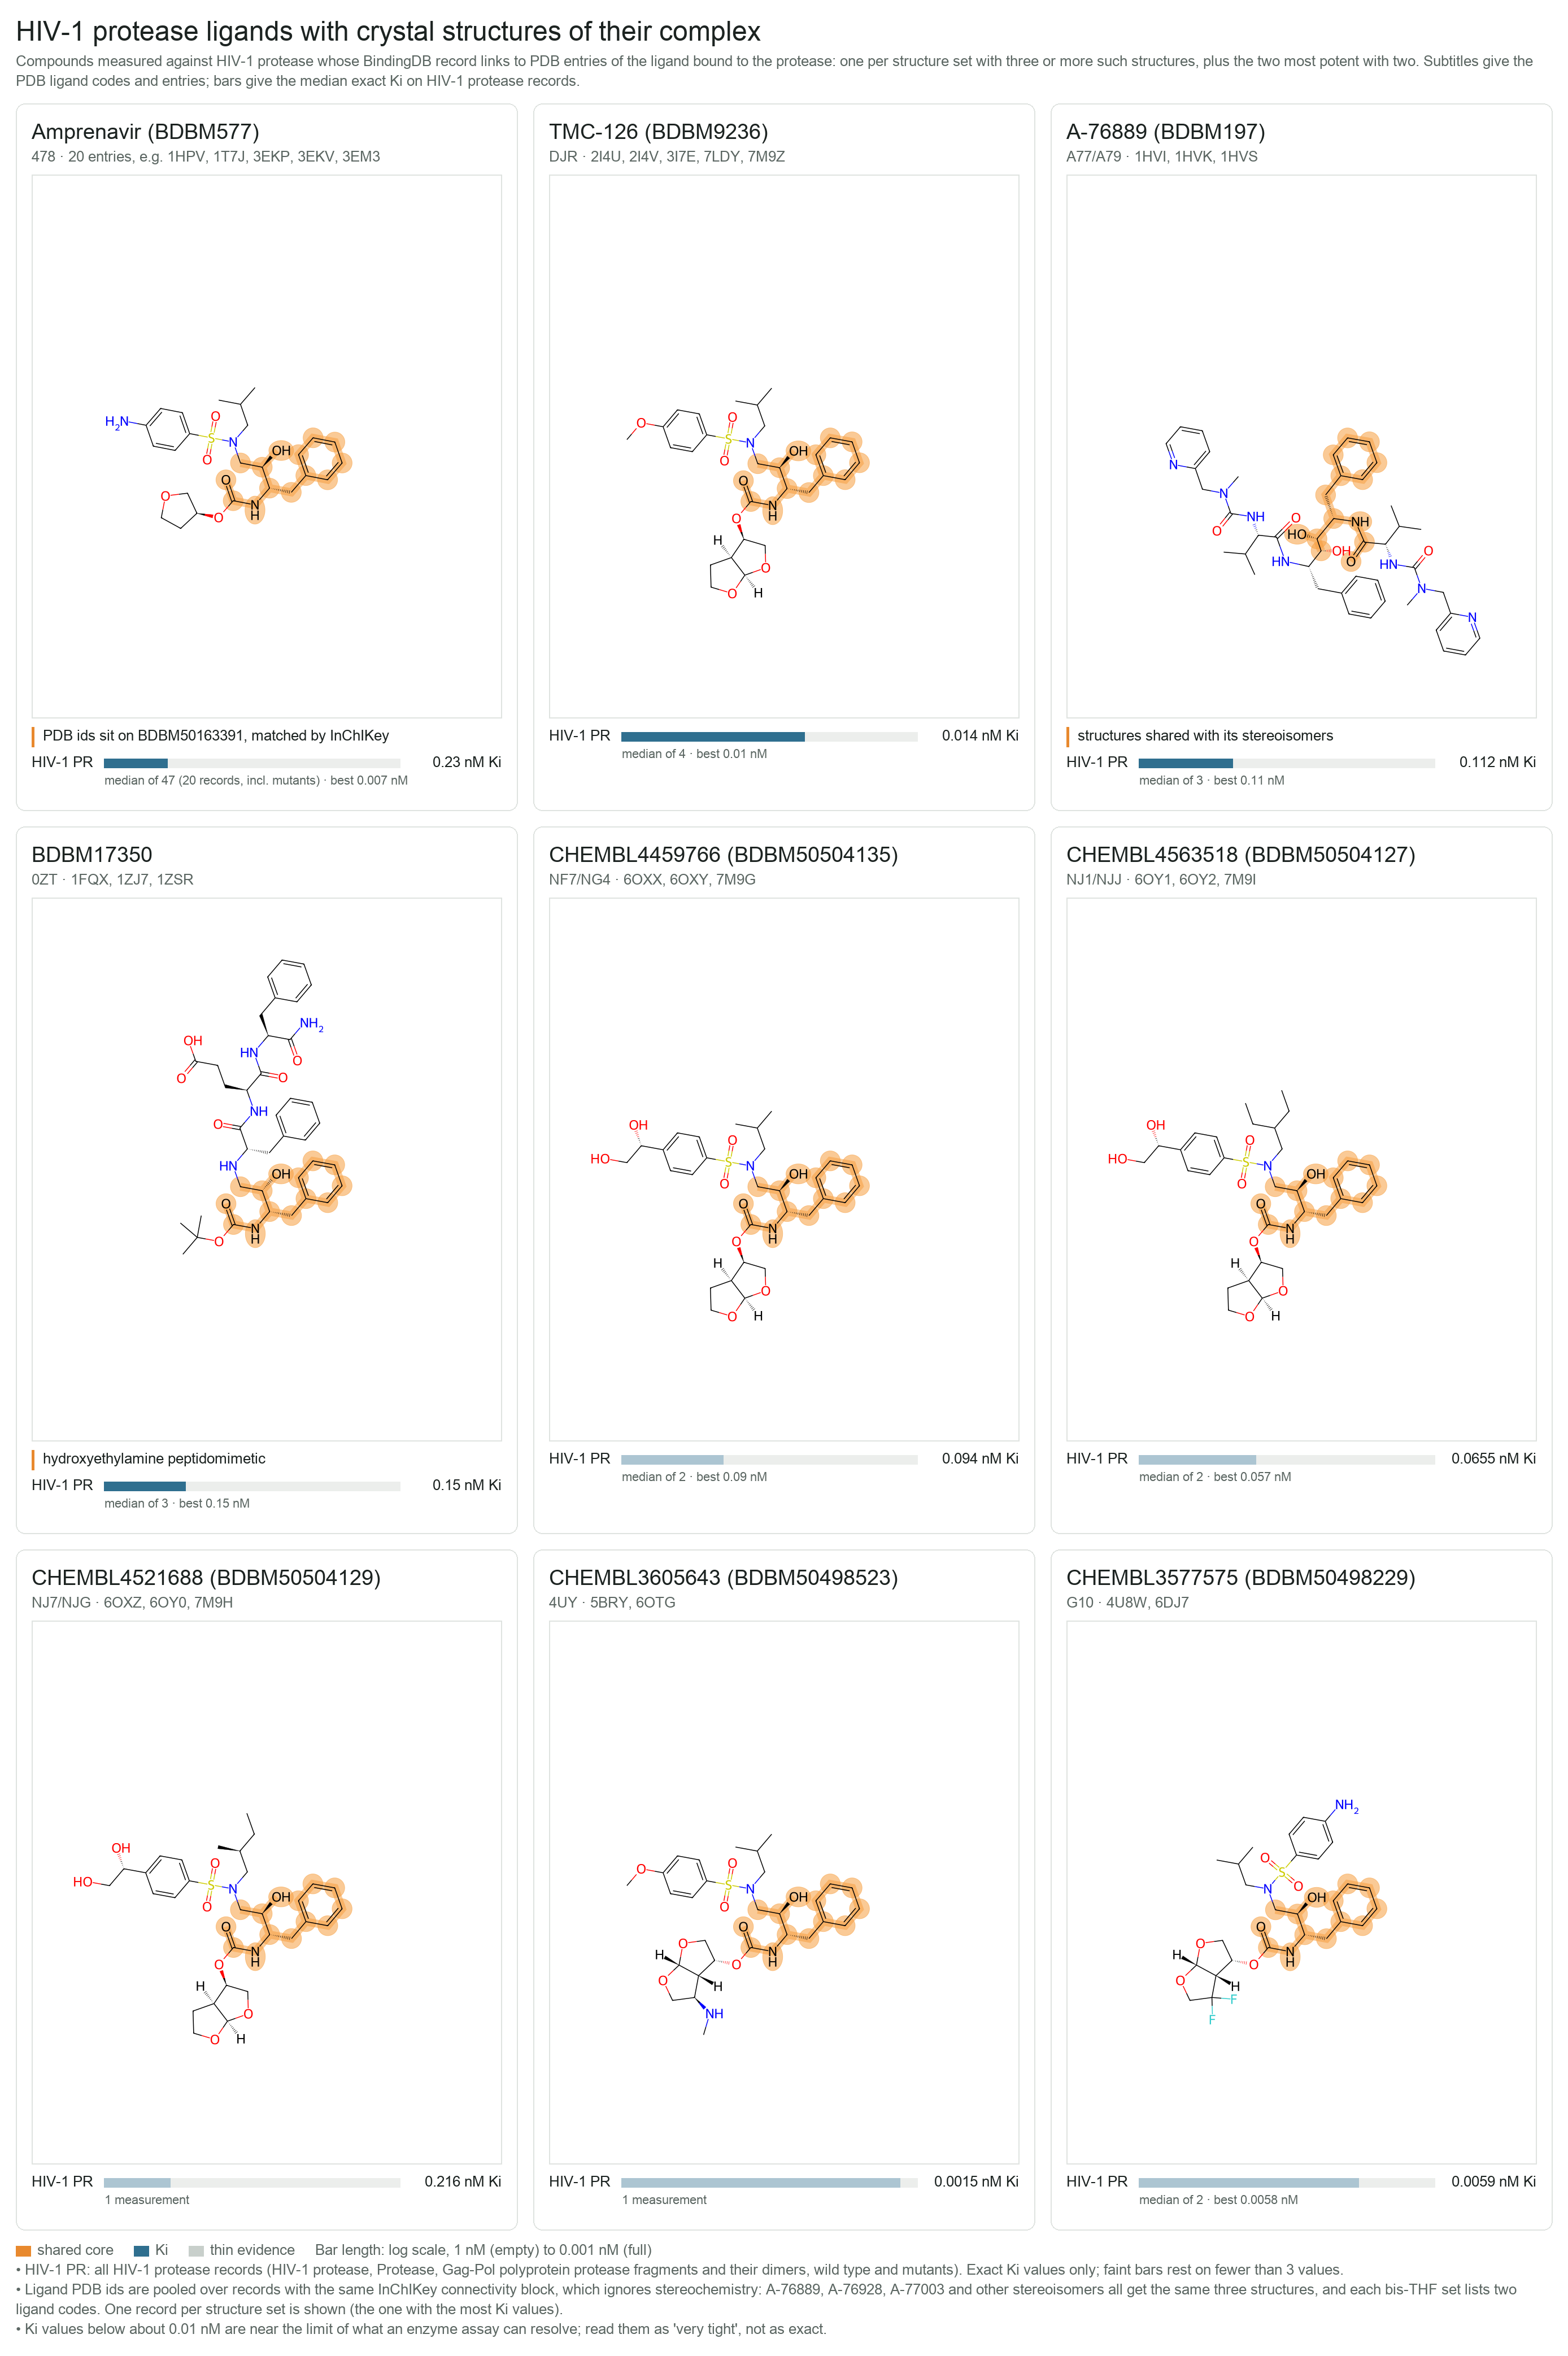

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'HIV-1 protease ligands with crystal structures of their complex',
    'compounds': [
        {
            'smiles': 'CC(C)CN(C[C@@H](O)[C@H](Cc1ccccc1)NC(=O)O[C@H]1CCOC1)S(=O)(=O)c1ccc(N)cc1 |r|',
            'title': 'Amprenavir (BDBM577)',
            'subtitle': '478 · 20 entries, e.g. 1HPV, 1T7J, 3EKP, 3EKV, 3EM3',
            'caption': 'PDB ids sit on BDBM50163391, matched by InChIKey',
            'bars': [
                {
                    'label': 'HIV-1 PR',
                    'value_nm': 0.23,
                    'type': 'Ki',
                    'note': 'median of 47 (20 records, incl. mutants) · best 0.007 nM',
                },
            ],
        },
        {
            'smiles': 'COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C[C@@H](O)[C@H](Cc1ccccc1)NC(=O)O[C@H]1CO[C@H]2OCC[C@@H]12 |@:11|',
            'title': 'TMC-126 (BDBM9236)',
            'subtitle': 'DJR · 2I4U, 2I4V, 3I7E, 7LDY, 7M9Z',
            'bars': [
                {
                    'label': 'HIV-1 PR',
                    'value_nm': 0.014,
                    'type': 'Ki',
                    'note': 'median of 4 · best 0.01 nM',
                },
            ],
        },
        {
            'smiles': 'CC(C)[C@H](NC(=O)N(C)Cc1ccccn1)C(=O)N[C@@H](Cc1ccccc1)[C@@H](O)[C@H](O)[C@H](Cc1ccccc1)NC(=O)[C@@H](NC(=O)N(C)Cc1ccccn1)C(C)C |r|',
            'title': 'A-76889 (BDBM197)',
            'subtitle': 'A77/A79 · 1HVI, 1HVK, 1HVS',
            'caption': 'structures shared with its stereoisomers',
            'bars': [
                {
                    'label': 'HIV-1 PR',
                    'value_nm': 0.112,
                    'type': 'Ki',
                    'note': 'median of 3 · best 0.11 nM',
                },
            ],
        },
        {
            'smiles': 'CC(C)(C)OC(=O)N[C@@H](Cc1ccccc1)[C@H](CN[C@@H](Cc2ccccc2)C(=O)N[C@@H](CCC(=O)O)C(=O)N[C@@H](Cc3ccccc3)C(=O)N)O',
            'title': 'BDBM17350',
            'subtitle': '0ZT · 1FQX, 1ZJ7, 1ZSR',
            'caption': 'hydroxyethylamine peptidomimetic',
            'bars': [
                {
                    'label': 'HIV-1 PR',
                    'value_nm': 0.15,
                    'type': 'Ki',
                    'note': 'median of 3 · best 0.15 nM',
                },
            ],
        },
        {
            'smiles': 'CC(C)CN(C[C@H]([C@H](Cc1ccccc1)NC(=O)O[C@H]2CO[C@@H]3[C@H]2CCO3)O)S(=O)(=O)c4ccc(cc4)[C@H](CO)O',
            'title': 'CHEMBL4459766 (BDBM50504135)',
            'subtitle': 'NF7/NG4 · 6OXX, 6OXY, 7M9G',
            'bars': [
                {
                    'label': 'HIV-1 PR',
                    'value_nm': 0.094,
                    'type': 'Ki',
                    'note': 'median of 2 · best 0.09 nM',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CCC(CC)CN(C[C@H]([C@H](Cc1ccccc1)NC(=O)O[C@H]2CO[C@@H]3[C@H]2CCO3)O)S(=O)(=O)c4ccc(cc4)[C@H](CO)O',
            'title': 'CHEMBL4563518 (BDBM50504127)',
            'subtitle': 'NJ1/NJJ · 6OY1, 6OY2, 7M9I',
            'bars': [
                {
                    'label': 'HIV-1 PR',
                    'value_nm': 0.0655,
                    'type': 'Ki',
                    'note': 'median of 2 · best 0.057 nM',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CC[C@H](C)CN(C[C@H]([C@H](Cc1ccccc1)NC(=O)O[C@H]2CO[C@@H]3[C@H]2CCO3)O)S(=O)(=O)c4ccc(cc4)[C@H](CO)O',
            'title': 'CHEMBL4521688 (BDBM50504129)',
            'subtitle': 'NJ7/NJG · 6OXZ, 6OY0, 7M9H',
            'bars': [
                {
                    'label': 'HIV-1 PR',
                    'value_nm': 0.216,
                    'type': 'Ki',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CC(C)CN(C[C@H]([C@H](Cc1ccccc1)NC(=O)O[C@H]2CO[C@@H]3[C@H]2[C@H](CO3)NC)O)S(=O)(=O)c4ccc(cc4)OC',
            'title': 'CHEMBL3605643 (BDBM50498523)',
            'subtitle': '4UY · 5BRY, 6OTG',
            'bars': [
                {
                    'label': 'HIV-1 PR',
                    'value_nm': 0.0015,
                    'type': 'Ki',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CC(C)CN(C[C@H]([C@H](Cc1ccccc1)NC(=O)O[C@H]2CO[C@@H]3[C@H]2C(CO3)(F)F)O)S(=O)(=O)c4ccc(cc4)N',
            'title': 'CHEMBL3577575 (BDBM50498229)',
            'subtitle': 'G10 · 4U8W, 6DJ7',
            'bars': [
                {
                    'label': 'HIV-1 PR',
                    'value_nm': 0.0059,
                    'type': 'Ki',
                    'note': 'median of 2 · best 0.0058 nM',
                    'faint': True,
                },
            ],
        },
    ],
    'columns': 3,
    'description': 'Compounds measured against HIV-1 protease whose BindingDB record links to PDB entries of the ligand bound to the protease: one per structure set with three or more such structures, plus the two most potent with two. Subtitles give the PDB ligand codes and entries; bars give the median exact Ki on HIV-1 protease records.',
    'notes': [
        'HIV-1 PR: all HIV-1 protease records (HIV-1 protease, Protease, Gag-Pol polyprotein protease fragments and their dimers, wild type and mutants). Exact Ki values only; faint bars rest on fewer than 3 values.',
        'Ligand PDB ids are pooled over records with the same InChIKey connectivity block, which ignores stereochemistry: A-76889, A-76928, A-77003 and other stereoisomers all get the same three structures, and each bis-THF set lists two ligand codes. One record per structure set is shown (the one with the most Ki values).',
        "Ki values below about 0.01 nM are near the limit of what an enzyme assay can resolve; read them as 'very tight', not as exact.",
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

**7,055 compounds** have a measurement on an HIV-1 protease record in BindingDB. **94** of them are linked to **106 PDB entries** in which the ligand is bound to HIV-1 protease. The grid below shows one compound for each set of three or more structures, plus the two most potent of those with two. Each card gives the PDB ligand codes and entries and a bar for the compound's Ki against the protease.

**Amprenavir** (BDBM577, ligand code 478) leads by far, with 20 protease structures (1HPV, 1T7J, 3EKP, 3EKV, 3EM3, 3NU3, 3NU4, 3NU5, 3NU6, 3NU9, 3NUJ, 3NUO, 3OXV, 3S43, 3S45, 4JEC, 4RVJ, 5KR0, 5T8H, 7N6V) and 58 protease measurements (47 exact Ki values on 20 protease records, wild type and mutants). TMC-126 (BDBM9236) has five structures, and five structure sets have three each: the A-76889 / A-76928 / A-77003 stereoisomers (1HVI, 1HVK, 1HVS), the hydroxyethylamine peptidomimetic BDBM17350, and three bis-THF sulfonamides from one series, CHEMBL4459766, CHEMBL4563518 and CHEMBL4521688. The last two cards, CHEMBL3605643 and CHEMBL3577575, have two structures each and the tightest Ki values in the set (1.5 pM and 6 pM), each from one or two measurements. All nine share the hydroxy-benzyl-ethyl amide or carbamate fragment of the transition-state isostere (C(=O)NH–CH(CH₂Ph)–CH(OH)–), which `draw_structure_grid` found as their 14-atom common core and highlights; seven of the nine also carry an N-alkyl arylsulfonamide like amprenavir's.

This is a good starting set if you want to relate measured affinity to binding mode, because each compound has both potency data and a structure of its complex with the protease.

**Lessons about cross-references.** This query looks simple but needs four things to come out right:

1. **The target has many names.** HIV-1 protease is a homodimer cut from the Gag-Pol polyprotein. BindingDB records it as "HIV-1 protease", "Protease", "Gag-Pol polyprotein [489-587]", "Dimer of Gag-Pol polyprotein [501-599]" and dozens of mutant and subtype constructs, as both single proteins (83 records) and complexes (76). The query uses a regular expression for these names. Plain "Gag-Pol polyprotein" records are left out, because the same name is also used for reverse transcriptase. A first version of the pattern also caught two "HIV-1 Protease substrate" records and an HIV-2 protease fragment (Gag-Pol polyprotein [514-612] from HIV-2); none has measurements, but the HIV-2 record's PDB ids would have counted HIV-2 structures, so the final pattern excludes them.
2. **PDB links sit on one compound record.** Amprenavir's protease measurements are on BDBM577, but its PDB ids (ligand code 478, 26 entries of which 20 are protease structures in BindingDB) are attached to a different record, BDBM50163391, which has a single measurement. Joining on monomerid finds nothing. Matching on the first 14 characters of the InChIKey (the connectivity block) connects the two records.
3. **That match ignores stereochemistry.** The first InChIKey block is the same for all stereoisomers. Seven records of the A-76928 diol and its stereoisomers (A-76889, A-76928, A-77003 and four others) are all assigned the same three structures, under two ligand codes (A77 and A79), and each bis-THF structure set is shared by two stereoisomers with two ligand codes. The 94 count is therefore an upper bound, and the grid keeps one record per structure set: the one with the most exact Ki values (ties: the lowest median). Which stereoisomer is in which crystal cannot be told from BindingDB.
4. **Coverage is incomplete.** Indinavir (BDBM517 and BDBM50067593, 141 measurements) and several other approved protease inhibitors have many PDB structures, but BindingDB carries no PDB link for them. A search of `monomer.het_pdb` for their ligand codes (MK1 indinavir, 017 darunavir, ROC saquinavir, RIT ritonavir, 1UN nelfinavir, DR7 atazanavir, AB1 lopinavir, TPV tipranavir) finds only amprenavir's 478. The 94 count is therefore also a lower bound on what the PDB actually holds. To check a specific compound, search the PDB by its InChIKey or ligand code.

The counts also depend on which constructs you call "HIV-1 protease": the target names were matched with

```sql
(regexp_matches(name, '^(Dimer of )?Gag-Pol polyprotein \[(4[89]\d|5[01]\d)-(5[89]\d|6[01]\d)[,\]]')
 OR ((name ILIKE 'HIV-1 protease%' OR name ILIKE 'Protease')
     AND (organism ILIKE '%immunodeficiency virus%' OR organism IS NULL)))
AND name NOT ILIKE '%substrate%' AND coalesce(organism, '') NOT ILIKE '%virus 2%'
```

which keeps the protease fragments (residues about 482–612 of Gag-Pol) and drops reverse transcriptase and integrase fragments, the substrate records and HIV-2. These 159 records carry 848 PDB entries; a narrower pattern drops a few mutant constructs and with them a few PDB entries.

Compared with release 202610 the counts are the same (7,055 ligands, 94 with structures, 106 entries). Two things in the figure differ from the earlier version of this example: the A77/A79 structure set is now represented by A-76889 rather than A-76928 (the selection rule is stated above; the earlier text said it kept the most potent stereoisomer but showed A-76928, whose median Ki of 1.3 nM is the weaker of the two with three Ki values each), and the highlighted core is now the 14-atom isostere fragment shared by all nine compounds rather than the hydroxyethylamine sulfonamide core shared by seven.

**How this was answered**

- `run_sql` on `target` finds the HIV-1 protease records, both single proteins and complexes, with the pattern above; a second query checks its edge cases (substrate records, HIV-2).
- `search_compounds` resolves amprenavir (BDBM577) and indinavir (BDBM517).
- `run_sql` lists every record sharing their InChIKey connectivity block: the records that hold their measurements carry no PDB links, and the InChIKey block links BDBM577 to BDBM50163391, which holds amprenavir's PDB ids.
- `run_sql` searches `monomer.het_pdb` for known protease-inhibitor ligand codes. Only amprenavir's 478 is present, on BDBM50163391.
- `run_sql` combines it all: the protease ligands, their PDB ids (pooled by InChIKey block), and the PDB ids of the protease protein records (`polymer.pdb_ids`, `complex.pdb_ids`). It counts the overlap, then lists the compounds with two or more structures with their Ki values. The comma-separated id lists are split with `unnest(string_split(...))`.
- `draw_structure_grid`: the nine compounds with their PDB ids as subtitles and a protease Ki bar each, aligned on the common core it found; compounds with fewer than three Ki values are drawn faint.

**Try next**

- "Which of these ligands bind the protease below 1 nM?" — add a `max_value_nm` filter (Example 3.1)
- "How do amprenavir's Ki values change across the drug-resistant protease mutants?"

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 9 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 8.6 — PDB cross-links: HIV-1 protease ligands with crystal structures, 2026-11-23, with claude-opus-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```